# Regression Trees

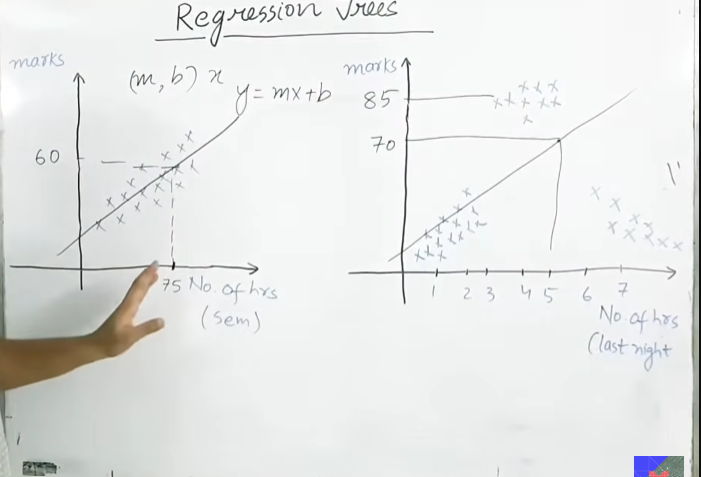

- For the first case where data is linear over the whole range, we use Linear Regression. 

- For the second case where data is non-linear but can be split into segments, we can use Regression Trees.

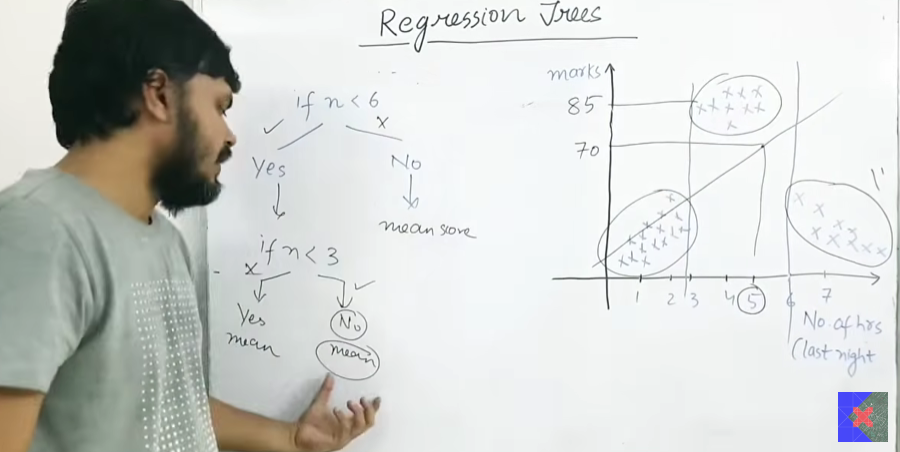

- The main thing is for the above case,segments were visible clearly so we could easily identify the segments and return the mean of the target variable (y) for each segment.

- But for continuous data, we cannot easily identify the the feature conditions to split the data into segments.

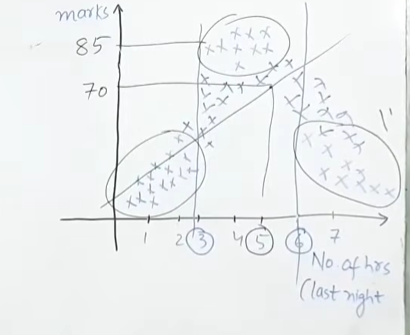

### So, to find the splitting conditions:

1. Take 2 points in the data and draw a line between them (find mean). And based on that line, split the data into 2 segments.

2. For each segment, calculate the mean of the target variable (y) and compute the sum of squared errors (SSE) using the mean line for that segment.
    -  And then sum the SSEs of both segments to get the total SSE for that split.

3. Repeat the above steps for all possible pairs of points in the data and find the pair that gives the minimum SSE.

4. So after the first split, we have 2 segments. Now we can repeat the above steps for each segment to find the next best split.
    - Do define a stopping criteria to stop the splitting process (Eg: minimum number of points in a segment, maximum depth of the tree, etc.)

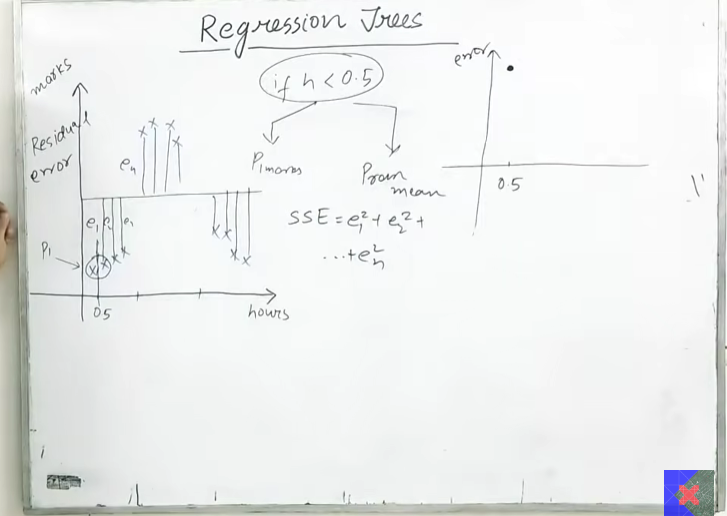

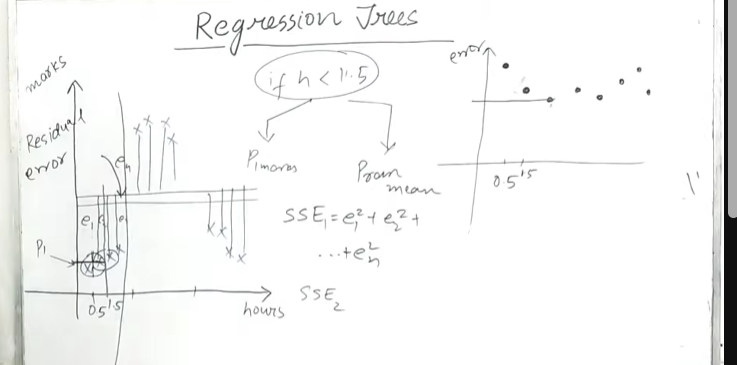

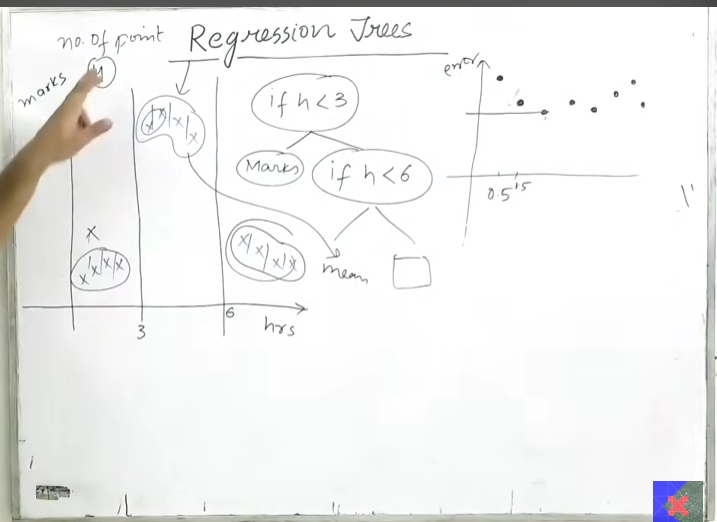

- In the above example, there was just one feature (x) and we split the data based on that feature. But what if we have multiple features?


## Regression Trees with Multiple Features

A Regression Tree splits the dataset into smaller segments such that the **Sum of Squared Errors (SSE)** within the segments is minimized.

### 1. Find the best split for each feature

- Consider one feature at a time (e.g., $X_1$).
- Sort the data points according to their feature values.
- Calculate the midpoint between every pair of consecutive feature values. Each midpoint acts as a potential splitting threshold.
- For every threshold:
  - Divide the data into two segments: left and right.
  - Calculate the mean of the target variable ($y$) in each segment.
  - Calculate the SSE for each segment using its respective mean as the prediction.
  - Add both SSEs to get the total SSE for that split.

**SSE Formula:**

$$
SSE = \sum_{i=1}^{n}(y_i-\bar{y})^2
$$

Where:
- $y_i$ = Actual target value.
- $\bar{y}$ = Mean target value of the segment.
- $n$ = Number of data points in the segment.

- Choose the threshold that gives the minimum total SSE. This becomes the best split for that feature.

### 2. Choose the best feature

- Repeat Step 1 for every available feature ($X_1, X_2, X_3, \ldots$).
- Compare the minimum SSE obtained for each feature.
- Select the feature and threshold that produce the lowest overall SSE.

### 3. Repeat the splitting process recursively

- Once the best split is selected, the dataset is divided into two child nodes.
- Repeat Steps 1 and 2 independently for each child node.
- Continue splitting until a stopping condition is reached.

### 4. Define stopping criteria

To prevent overfitting, define conditions such as:

- `max_depth`: Maximum depth of the tree.
- `min_samples_split`: Minimum number of samples required to split a node.
- `min_samples_leaf`: Minimum number of samples allowed in a leaf node.
- Minimum SSE reduction required to perform a split.

### Important Points to Remember

- A regression tree predicts the **mean of the target values** in each leaf node.
- The feature used for splitting is not necessarily the one with the highest correlation with $y$.
- The objective at every split is to minimize the total SSE of the resulting child nodes.

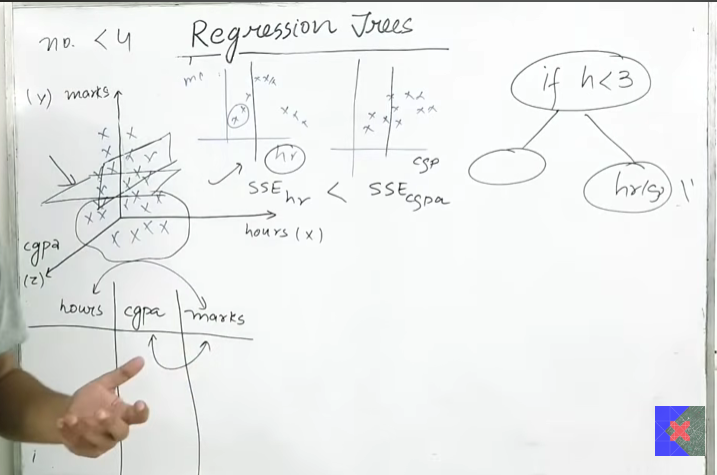

- Unlike classification trees, regression trees do not use metrics like Gini impurity or entropy. Instead, they focus on minimizing MSE (Mean Squared Error), MAE (Mean Absolute Error), or other regression-specific metrics for the target variable in the child nodes.


# Visual Demonstration of Regression Trees

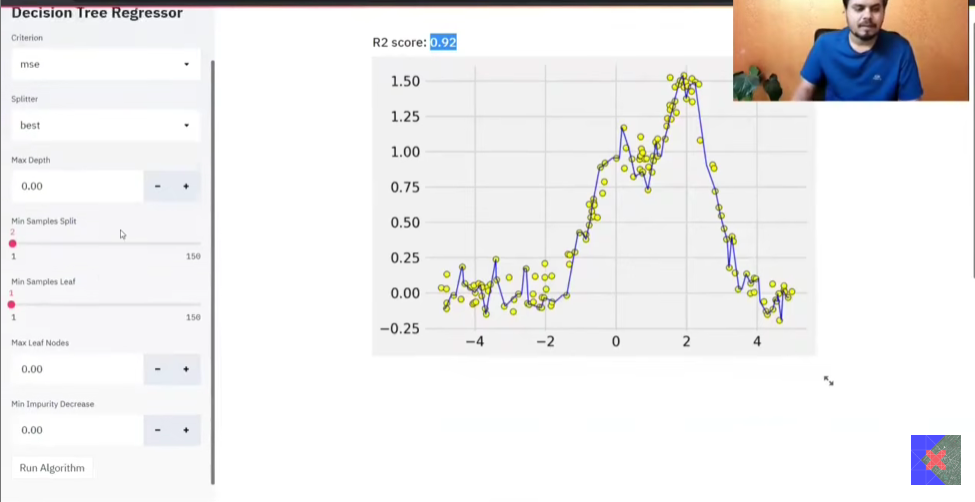

- For max_depth=1, the tree makes a single split and predicts the mean of the target variable for each segment. It underfits the data as it does not capture the underlying pattern.

- For larger max_depth values, the tree can make more splits, capturing more complex patterns in the data. However, if max_depth is too large, the tree may overfit the training data and perform poorly on unseen data.

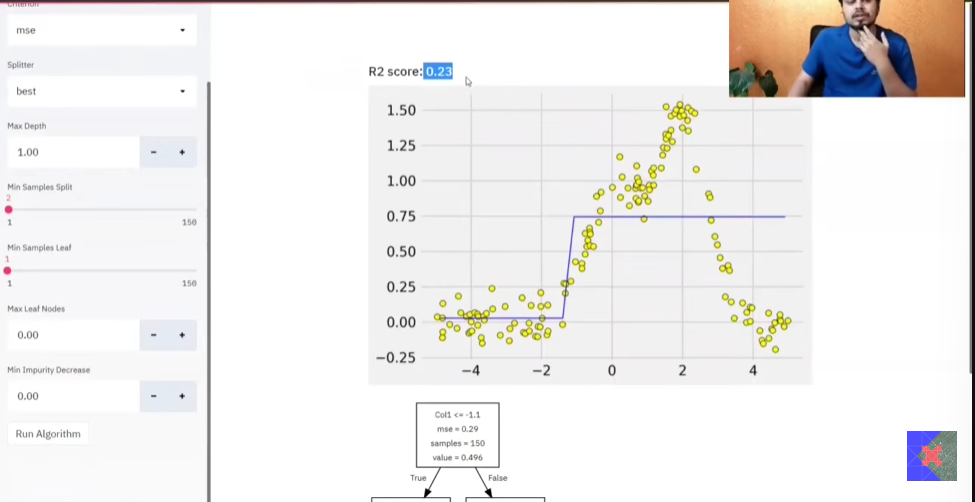



## Splitter Parameter in Decision Trees

The `splitter` parameter determines how the decision tree selects the splitting threshold.

### 1. When `splitter='best'`

The algorithm:

1. Considers different splitting thresholds for each feature ($X_1$, $X_2$, etc.).
2. Calculates the SSE for every possible split.
3. Compares the SSE values across all considered features.
4. Selects the feature and threshold that produce the minimum SSE.

**Example:**

| Feature | Threshold | SSE |
|:---|---:|---:|
| $X_1$ | 10 | 120 |
| $X_1$ | 15 | 90 |
| $X_1$ | 20 | 100 |
| $X_2$ | 5 | 110 |
| $X_2$ | 10 | 70 |
| $X_2$ | 15 | 95 |

**Best Split:** $X_2 \leq 10$, because it gives the minimum SSE of 70.

### 2. When `splitter='random'`

Instead of evaluating every possible threshold, the algorithm:

1. Considers the available features.
2. Randomly generates candidate splitting thresholds for the features considered.
3. Calculates the SSE for each randomly generated candidate.
4. Selects the candidate that produces the minimum SSE among the generated candidates.

**Example:**

Suppose the algorithm randomly generates the following candidate thresholds:

| Feature | Random Threshold | SSE |
|:---|---:|---:|
| $X_1$ | 12 | 105 |
| $X_1$ | 18 | 95 |
| $X_2$ | 7 | 85 |
| $X_2$ | 13 | 100 |

**Selected Split:** $X_2 \leq 7$, because it has the lowest SSE (85) among the randomly generated candidates.

**Observation:** The algorithm may not find the globally best split (SSE = 70), since it evaluates only randomly generated candidate thresholds.

### Important Points

- `splitter='best'`: Evaluates all possible split thresholds for the features considered and selects the best one.
- `splitter='random'`: Generates random candidate thresholds and selects the best among them.
- Random splitting can produce different trees for the same dataset.
- `max_features` controls how many features are considered for splitting, whereas `splitter` controls how candidate thresholds are generated and selected.

**Remember:** Random does not mean blindly selecting a feature or threshold. The generated candidate splits are still evaluated based on their **impurity reduction**.

## Remaining hyperparameters for Regression Trees

- All other existing hyperparameters for Decision trees that we discussed earlier are also applicable to Regression Trees. 



## Impurity Reduction in Decision Trees

Impurity reduction means how much the impurity decreases after splitting a parent node into two child nodes.

In simple terms, we want the resulting child nodes to be more homogeneous (contain more similar data points) than the parent node.

### 1. In Regression Trees

- For regression trees, impurity is measured using **SSE (Sum of Squared Errors)**.
- Consider a parent node containing 100 data points.

**Before splitting:**
- Parent SSE = 500

**After splitting:**
- Left child SSE = 150
- Right child SSE = 200
- Total SSE of children = 350

**Impurity Reduction Formula:**

$$
\text{Impurity Reduction}
= SSE_{\text{parent}} - SSE_{\text{children}}
$$

$$
= 500 - (150 + 200) = 150
$$

Therefore, the impurity reduction is **150**.

The split has reduced the total error by 150.

### 2. In Classification Trees

Impurity is generally measured using:

- Gini Impurity
- Entropy

The algorithm chooses the split that produces the maximum reduction in impurity.

### 3. Important Formulas to Remember

**Information Gain (Entropy Reduction):**

$$
\text{Information Gain}
= H(\text{Parent}) - H(\text{Children})
$$

More precisely, the children’s impurity is calculated as a weighted average:

$$
IG = H(P) - \left(
\frac{N_L}{N}H(L) +
\frac{N_R}{N}H(R)
\right)
$$

**SSE Reduction (Regression):**

$$
\Delta SSE =
SSE_{\text{Parent}} - SSE_{\text{Children}}
$$

### Key Takeaways

- A good split creates child nodes that are more homogeneous than the parent node.
- Regression → Minimize SSE (or equivalently, maximize SSE reduction).
- Classification → Minimize Gini/Entropy (or maximize impurity reduction).


# Feature Importance in Decision Trees

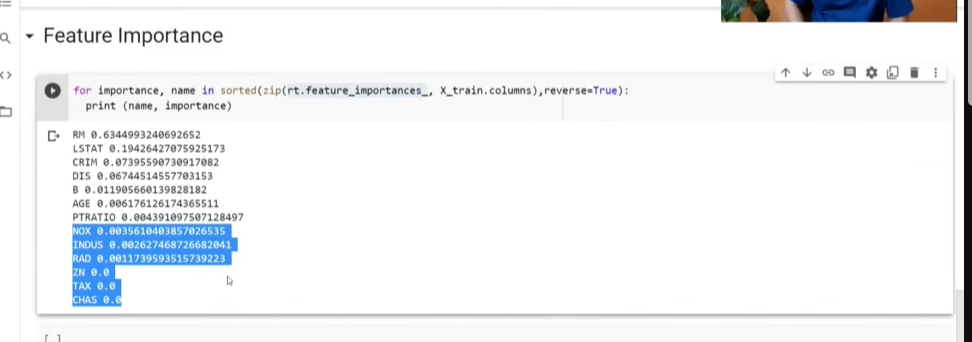

- Feature importance measures how much each feature contributes to the predictions made by the decision tree.
- It can be used for feature selection, to identify which features are most relevant for the target variable.